In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle, FancyBboxPatch
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
import warnings
warnings.filterwarnings('ignore')
import io

In [3]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 100  # For notebook display
plt.rcParams['savefig.dpi'] = 300  # For saving

In [ ]:
COLORS = {
    'dmae': '#5485AB',      # Blue - Distance metrics
    'mae': '#5485AB',       # Alias for distance metrics
    'angle': '#BA4682',     # Magenta - Angular metrics
    'clash': '#E18922',     # Orange - Steric clash
    'runtime': '#CD81A8',   # Light magenta - Runtime
    'time': '#6AAAA5',      # Alias for runtime
    'target': '#007E71',    # Green - Target/optimal zones
    'ts_line': '#646363',   # Dark gray - TS reference
}

In [36]:
# Load and parse the data
csv_text = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples
TS,0.143,0.458,6.156,37.228,32.947,0.153,25.0,50.0
TS,0.152,0.439,6.598,36.007,4.398,0.316,50.0,50.0
TS,0.15,0.454,6.543,36.903,52.478,0.06,10.0,50.0
TS,0.141,0.416,6.323,33.804,15.287,0.231,25.0,75.0
TS,0.156,0.515,6.582,41.536,7.612,0.064,25.0,20.0
all,0.149,0.475,6.609,38.345,5.483,1.262,25.0,50.0
0,0.294,0.726,15.28,50.424,12.338,0.064,25.0,20.0
1,0.277,0.675,14.443,46.649,2.835,0.063,25.0,20.0
2,0.255,0.63,13.321,43.804,1.967,0.064,25.0,20.0
3,0.229,0.586,11.861,43.672,15.524,0.064,25.0,20.0
4,0.184,0.542,8.875,42.516,2.679,0.065,25.0,20.0
5,0.149,0.504,6.428,39.819,6.814,0.063,25.0,20.0
6,0.206,0.518,9.486,39.712,24.029,0.065,25.0,20.0
7,0.259,0.598,11.226,43.067,52.506,0.063,25.0,20.0
8,0.301,0.654,12.603,43.82,33.595,0.064,25.0,20.0
9,0.335,0.71,13.288,46.466,29.989,0.063,25.0,20.0
0 to 3,0.29,0.704,14.85,48.354,5.08,0.246,25.0,20.0
2 to 6,0.15,0.502,6.653,40.362,2.453,0.425,25.0,20.0
6 to 9,0.21,0.544,9.596,41.302,21.61,0.249,25.0,20.0
"0,2,3,6,8",0.275,0.666,14.056,46.298,2.367,0.314,25.0,20.0
"0, 5, 9",0.186,0.549,8.611,43.993,2.54,0.185,25.0,20.0"""

csv_TS_special = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples,batch_size,lr
TS,0.185,0.523,8.361,41.26,16.839,0.058,25.0,20.0,64,0.0005
TS,0.143,0.458,6.156,37.228,32.947,0.153,25.0,50.0,128,0.0005
TS,0.123,0.492,4.971,38.791,1.645,0.082,25.0,20.0,256,0.0005
TS,0.113,0.487,4.43,38.588,1.769,0.097,25.0,20.0,344,0.0005
TS,0.099,0.481,3.968,37.58,1.483,0.125,25.0,20.0,512,0.0005
TS,0.212,0.531,10.244,42.641,45.203,0.063,25.0,20.0,128,0.0001
TS,0.133,0.498,5.628,39.5,2.172,0.063,25.0,20.0,128,0.001"""

csv_all_weights = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples
all-without-TS-weighting,0.159,0.47,7.507,37.801,2.511,1.527,25.0,50.0
all-with-TS-weighting,0.149,0.475,6.609,38.345,5.483,1.262,25.0,50.0"""

# Load into DataFrame
df = pd.read_csv(io.StringIO(csv_text))

# Rename columns to cleaner names
df.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples']

# Separate by configuration type for easier analysis
ts_df = df[df['config'] == 'TS'].reset_index(drop=True)
all_df = df[df['config'] == 'all'].reset_index(drop=True)
ablation_df = df[~df['config'].isin(['TS', 'all'])].reset_index(drop=True)

# Create long-form for faceted/grouped plots
metrics = ['mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time']
df_long = df.melt(id_vars=['config'], value_vars=metrics, var_name='metric', value_name='value')

# Load TS special experiments (with batch_size and lr variations)
df_ts_special = pd.read_csv(io.StringIO(csv_TS_special))
df_ts_special.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples', 'batch_size', 'lr']

# Load TS weighting comparison
df_all_weights = pd.read_csv(io.StringIO(csv_all_weights))
df_all_weights.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples']

print("Full dataset shape:", df.shape)
print("\nTS configurations:", len(ts_df))
print("All configurations:", len(all_df))
print("Ablation configurations:", len(ablation_df))
print("\n" + "="*60)
print("TS Special (batch_size/lr) experiments:", len(df_ts_special))
print("TS Weighting comparison:", len(df_all_weights))


Full dataset shape: (21, 9)

TS configurations: 5
All configurations: 1
Ablation configurations: 15

TS Special (batch_size/lr) experiments: 7
TS Weighting comparison: 2


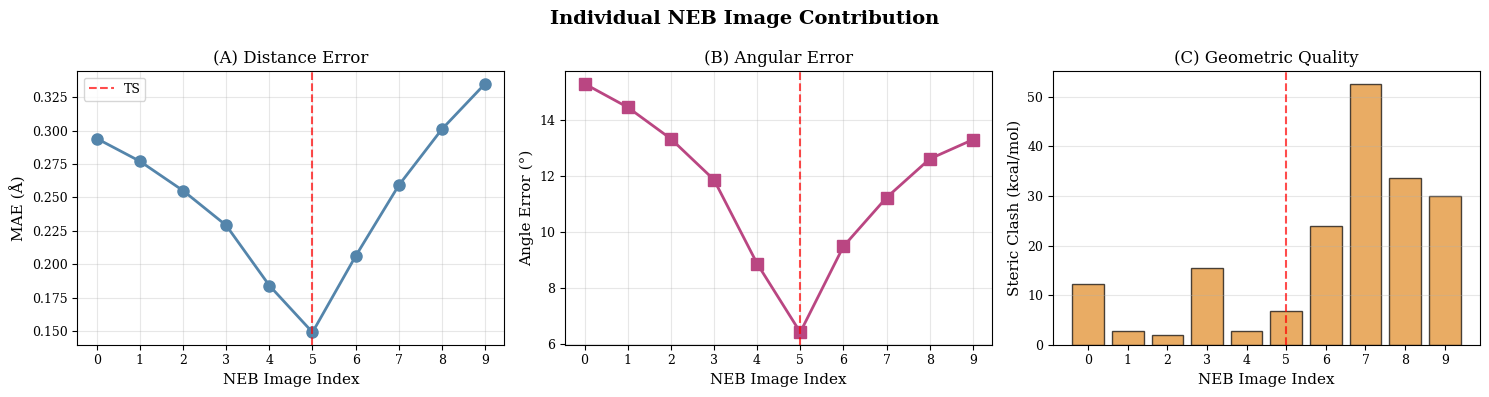

In [42]:
# ============================================================================
# FIGURE 1: Individual NEB Image Analysis
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Individual NEB Image Contribution', fontweight='bold')

# Filter single images
single_df = df[df['config'].isin(['0','1','2','3','4','5','6','7','8','9'])].copy()
single_df['img_idx'] = single_df['config'].astype(int)
single_df = single_df.sort_values('img_idx')

x = single_df['img_idx'].values

# Panel A: MAE
axes[0].plot(x, single_df['mae'], 'o-', color=COLORS['mae'], 
             linewidth=2, markersize=8)
axes[0].axvline(5, color='red', linestyle='--', alpha=0.7, label='TS')
axes[0].set_xlabel('NEB Image Index')
axes[0].set_ylabel('MAE (Å)')
axes[0].set_title('(A) Distance Error')
axes[0].grid(True, alpha=0.3)
axes[0].legend()
axes[0].set_xticks(range(10))

# Panel B: Angle Error
axes[1].plot(x, single_df['angle_error'], 's-', color=COLORS['angle'],
             linewidth=2, markersize=8)
axes[1].axvline(5, color='red', linestyle='--', alpha=0.7)
axes[1].set_xlabel('NEB Image Index')
axes[1].set_ylabel('Angle Error (°)')
axes[1].set_title('(B) Angular Error')
axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(range(10))

# Panel C: Steric Clash
axes[2].bar(x, single_df['steric_clash'], color=COLORS['clash'], 
            alpha=0.7, edgecolor='black')
axes[2].axvline(5, color='red', linestyle='--', alpha=0.7)
axes[2].set_xlabel('NEB Image Index')
axes[2].set_ylabel('Steric Clash (kcal/mol)')
axes[2].set_title('(C) Geometric Quality')
axes[2].grid(True, alpha=0.3, axis='y')
axes[2].set_xticks(range(10))

plt.tight_layout()
# plt.savefig('fig1_neb_images.png', dpi=300, bbox_inches='tight')
plt.show()


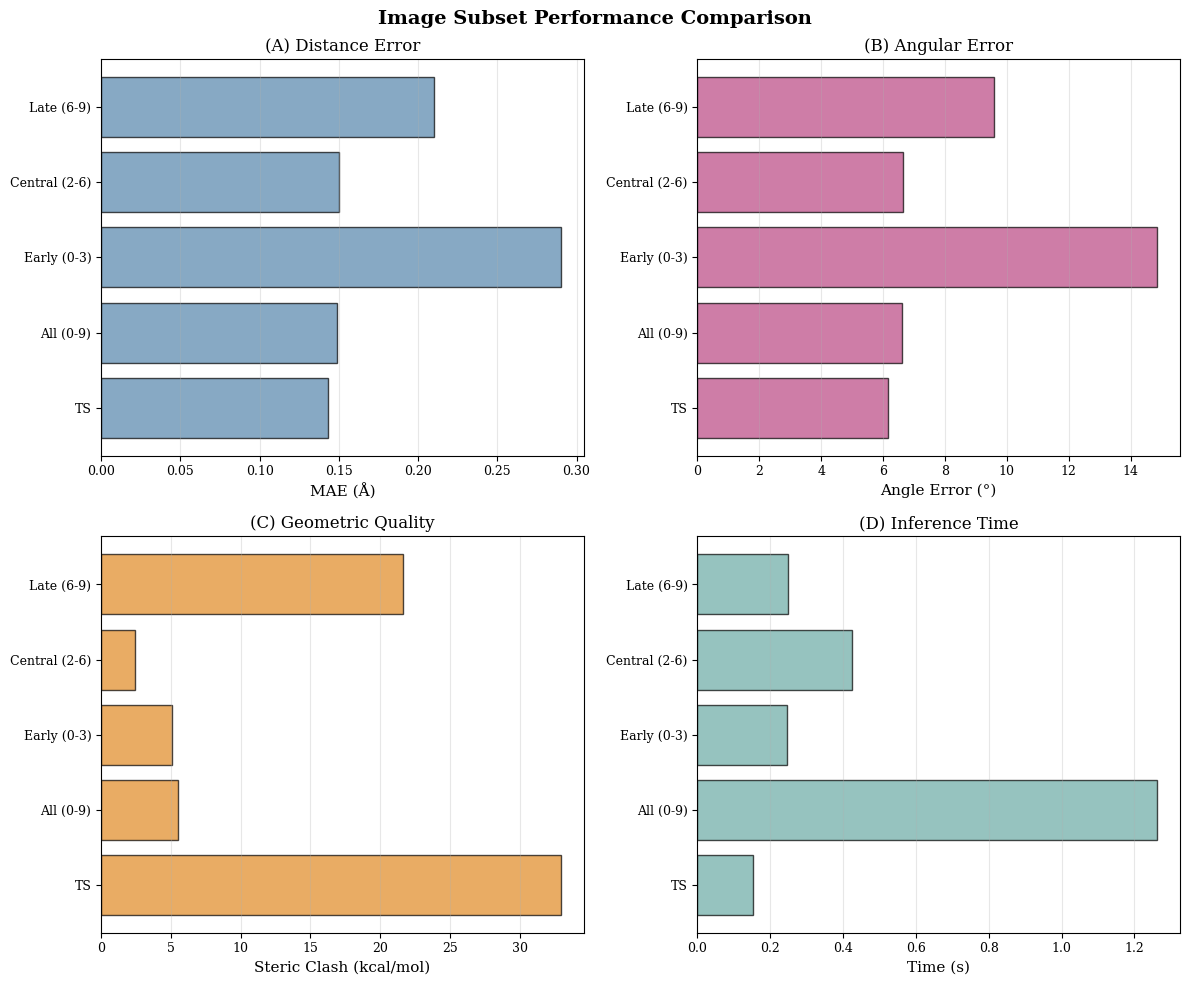

In [38]:
# ============================================================================
# FIGURE 2: Subset Comparison
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Image Subset Performance Comparison', fontweight='bold')

# Define subsets (matching config names in the CSV)
subsets = {
    'TS': df[df['config'] == 'TS'].iloc[0] if len(df[df['config'] == 'TS']) > 0 else None,
    'All (0-9)': df[df['config'] == 'all'].iloc[0] if len(df[df['config'] == 'all']) > 0 else None,
    'Early (0-3)': df[df['config'] == '0 to 3'].iloc[0] if len(df[df['config'] == '0 to 3']) > 0 else None,
    'Central (2-6)': df[df['config'] == '2 to 6'].iloc[0] if len(df[df['config'] == '2 to 6']) > 0 else None,
    'Late (6-9)': df[df['config'] == '6 to 9'].iloc[0] if len(df[df['config'] == '6 to 9']) > 0 else None,
}

subsets = {k: v for k, v in subsets.items() if v is not None}
labels = list(subsets.keys())

# Panel A: MAE
axes[0,0].barh(labels, [v['mae'] for v in subsets.values()], 
               color=COLORS['mae'], alpha=0.7, edgecolor='black')
axes[0,0].set_xlabel('MAE (Å)')
axes[0,0].set_title('(A) Distance Error')
axes[0,0].grid(True, alpha=0.3, axis='x')

# Panel B: Angle Error
axes[0,1].barh(labels, [v['angle_error'] for v in subsets.values()],
               color=COLORS['angle'], alpha=0.7, edgecolor='black')
axes[0,1].set_xlabel('Angle Error (°)')
axes[0,1].set_title('(B) Angular Error')
axes[0,1].grid(True, alpha=0.3, axis='x')

# Panel C: Steric Clash
axes[1,0].barh(labels, [v['steric_clash'] for v in subsets.values()],
               color=COLORS['clash'], alpha=0.7, edgecolor='black')
axes[1,0].set_xlabel('Steric Clash (kcal/mol)')
axes[1,0].set_title('(C) Geometric Quality')
axes[1,0].grid(True, alpha=0.3, axis='x')

# Panel D: Runtime
axes[1,1].barh(labels, [v['time'] for v in subsets.values()],
               color=COLORS['time'], alpha=0.7, edgecolor='black')
axes[1,1].set_xlabel('Time (s)')
axes[1,1].set_title('(D) Inference Time')
axes[1,1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
# plt.savefig('fig2_subsets.png', dpi=300, bbox_inches='tight')
plt.show()


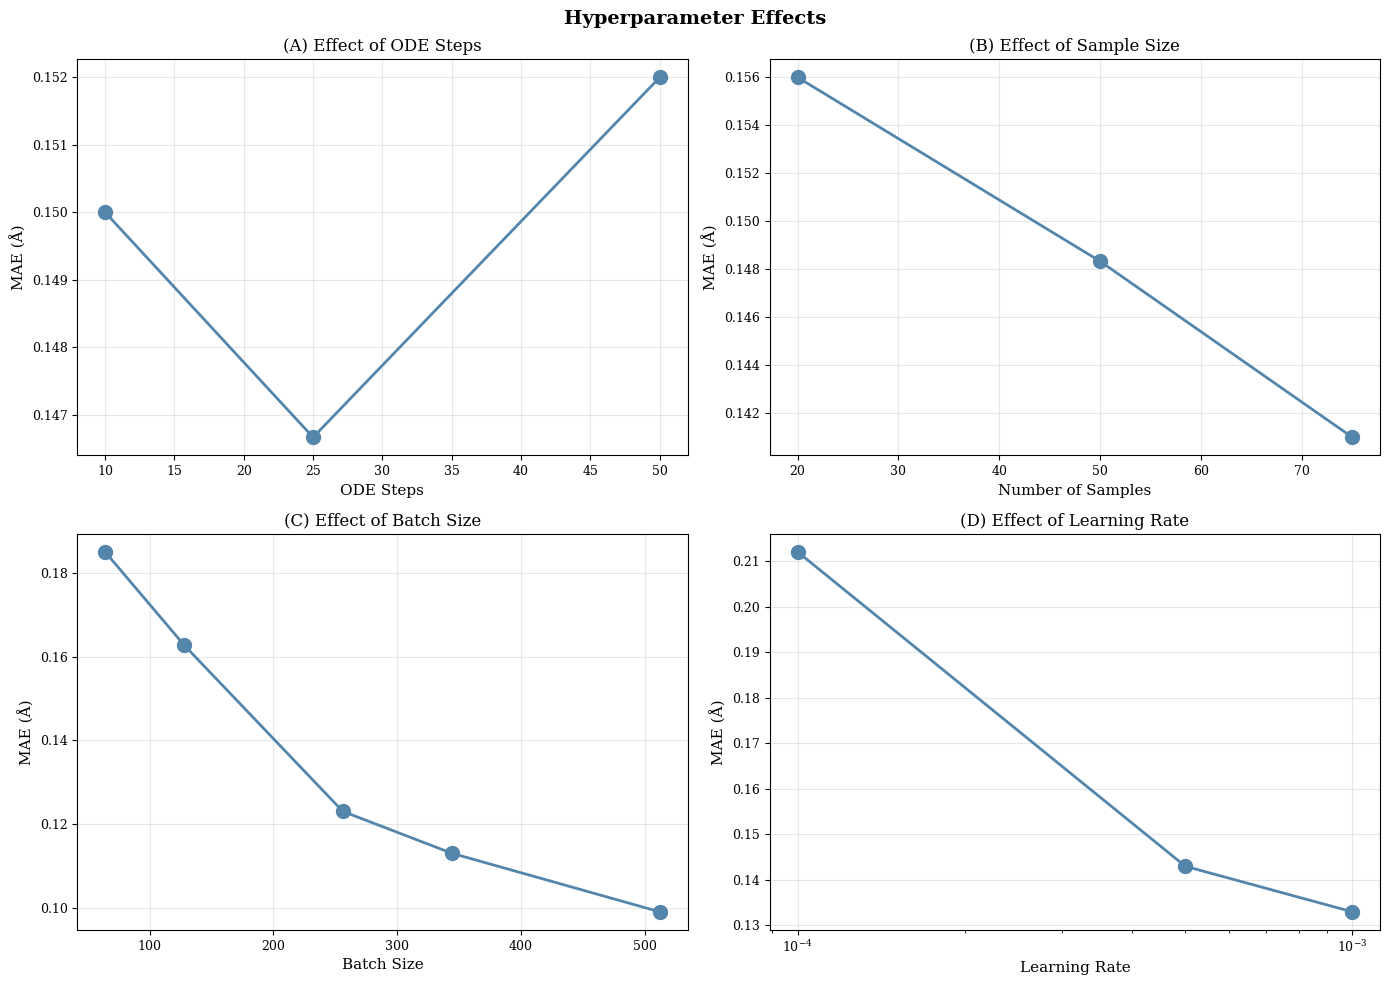

In [39]:
# ============================================================================
# FIGURE 3: Hyperparameters (ODE Steps, Samples, Batch Size, Learning Rate)
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Hyperparameter Effects', fontweight='bold')

# Panel A: ODE Steps
ts_df = df[df['config'] == 'TS'].copy()
ode_grouped = ts_df.groupby('ode_steps')['mae'].mean().sort_index()

axes[0,0].plot(ode_grouped.index, ode_grouped.values, 'o-', 
             color=COLORS['mae'], linewidth=2, markersize=10)
axes[0,0].set_xlabel('ODE Steps')
axes[0,0].set_ylabel('MAE (Å)')
axes[0,0].set_title('(A) Effect of ODE Steps')
axes[0,0].grid(True, alpha=0.3)

# Panel B: Sample Size
sample_grouped = ts_df.groupby('samples')['mae'].mean().sort_index()

axes[0,1].plot(sample_grouped.index, sample_grouped.values, 'o-',
             color=COLORS['mae'], linewidth=2, markersize=10)
axes[0,1].set_xlabel('Number of Samples')
axes[0,1].set_ylabel('MAE (Å)')
axes[0,1].set_title('(B) Effect of Sample Size')
axes[0,1].grid(True, alpha=0.3)

# Panel C: Batch Size (using df_ts_special)
batch_grouped = df_ts_special.groupby('batch_size')['mae'].mean().sort_index()

axes[1,0].plot(batch_grouped.index, batch_grouped.values, 'o-', 
             color=COLORS['mae'], linewidth=2, markersize=10)
axes[1,0].set_xlabel('Batch Size')
axes[1,0].set_ylabel('MAE (Å)')
axes[1,0].set_title('(C) Effect of Batch Size')
axes[1,0].grid(True, alpha=0.3)

# Panel D: Learning Rate (using df_ts_special)
# Filter for consistent batch_size (128) to isolate lr effect
lr_df = df_ts_special[df_ts_special['batch_size'] == 128].copy()
lr_grouped = lr_df.groupby('lr')['mae'].mean().sort_index()

axes[1,1].plot(lr_grouped.index, lr_grouped.values, 'o-',
             color=COLORS['mae'], linewidth=2, markersize=10)
axes[1,1].set_xlabel('Learning Rate')
axes[1,1].set_ylabel('MAE (Å)')
axes[1,1].set_title('(D) Effect of Learning Rate')
axes[1,1].set_xscale('log')  # Log scale for learning rate
axes[1,1].grid(True, alpha=0.3)


plt.tight_layout()
# plt.savefig('fig3_hyperparameters.png', dpi=300, bbox_inches='tight')
plt.show()


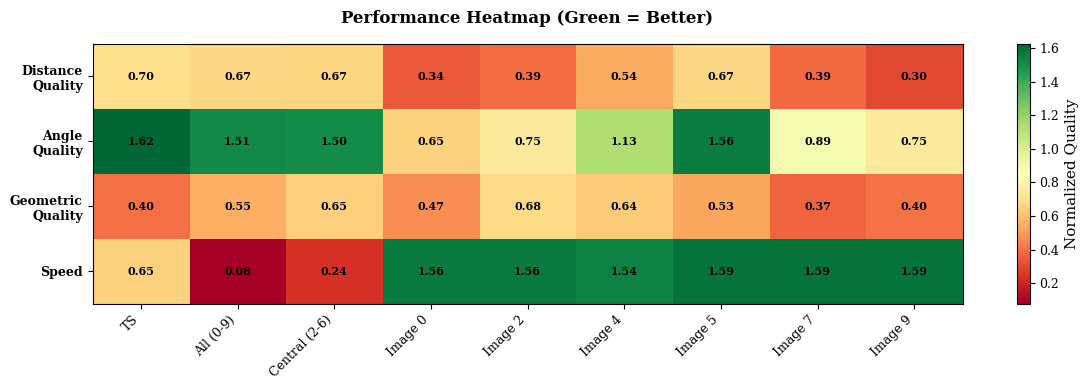

In [40]:
# ============================================================================
# FIGURE 4: Performance Heatmap
# ============================================================================

fig, ax = plt.subplots(figsize=(12, 4))

# Select key experiments for heatmap
heatmap_names = ['TS', 'All (0-9)', 'Central (2-6)', 'Image 0', 
                 'Image 2', 'Image 4', 'Image 5', 'Image 7', 'Image 9']
heatmap_data = []
heatmap_labels = []

for name in heatmap_names:
    if name == 'TS':
        row = df[df['config'] == 'TS'].iloc[0] if len(df[df['config'] == 'TS']) > 0 else None
    elif name == 'All (0-9)':
        row = df[df['config'] == 'all'].iloc[0] if len(df[df['config'] == 'all']) > 0 else None
    elif name == 'Central (2-6)':
        row = df[df['config'] == '2 to 6'].iloc[0] if len(df[df['config'] == '2 to 6']) > 0 else None
    elif name.startswith('Image'):
        idx = name.split()[-1]
        row = df[df['config'] == idx].iloc[0] if len(df[df['config'] == idx]) > 0 else None
    else:
        row = None
    
    if row is not None:
        # Normalize (invert so higher is better)
        mae_norm = 1.0 / (row['mae'] * 10)
        angle_norm = 1.0 / (row['angle_error'] / 10)
        clash_norm = 1.0 / (np.log10(row['steric_clash'] + 1) + 1)
        time_norm = 1.0 / (row['time'] * 10)
        
        heatmap_data.append([mae_norm, angle_norm, clash_norm, time_norm])
        heatmap_labels.append(name)

heatmap_array = np.array(heatmap_data)
metrics = ['Distance\nQuality', 'Angle\nQuality', 'Geometric\nQuality', 'Speed']

im = ax.imshow(heatmap_array.T, cmap='RdYlGn', aspect='auto')
ax.set_yticks(range(len(metrics)))
ax.set_yticklabels(metrics, fontweight='bold')
ax.set_xticks(range(len(heatmap_labels)))
ax.set_xticklabels(heatmap_labels, rotation=45, ha='right')
ax.set_title('Performance Heatmap (Green = Better)', fontweight='bold', pad=15)

plt.colorbar(im, ax=ax, label='Normalized Quality')

# Add values
for i in range(len(heatmap_labels)):
    for j in range(len(metrics)):
        ax.text(i, j, f'{heatmap_array[i, j]:.2f}',
                ha="center", va="center", fontsize=8, fontweight='bold')

plt.tight_layout()
# plt.savefig('fig4_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


In [10]:
# ============================================================================
# SUMMARY STATISTICS
# ============================================================================

print("\n" + "="*80)
print("KEY STATISTICS")
print("="*80)

ts_baseline = df[df['config'] == 'TS'].iloc[0]
print(f"\nBaseline (TS-Only):")
print(f"  MAE: {ts_baseline['mae']:.3f} Å")
print(f"  Angle Error: {ts_baseline['angle_error']:.2f}°")
print(f"  Time: {ts_baseline['time']:.3f} s")

best_single = single_df.nsmallest(1, 'mae').iloc[0]
print(f"\nBest Single Image:")
print(f"  Image {int(best_single['img_idx'])}: MAE = {best_single['mae']:.3f} Å")

if 'Central (2-6)' in subsets:
    central = subsets['Central (2-6)']
    print(f"\nBest Subset (Central 2-6):")
    print(f"  MAE: {central['mae']:.3f} Å")
    print(f"  Angle Error: {central['angle_error']:.2f}°")
    print(f"  Time: {central['time']:.3f} s")

print("\n" + "="*80)
print("✓ All figures saved!")
print("="*80)








KEY STATISTICS

Baseline (TS-Only):
  MAE: 0.143 Å
  Angle Error: 6.16°
  Time: 0.153 s

Best Single Image:
  Image 5: MAE = 0.149 Å

Best Subset (Central 2-6):
  MAE: 0.150 Å
  Angle Error: 6.65°
  Time: 0.425 s

✓ All figures saved!


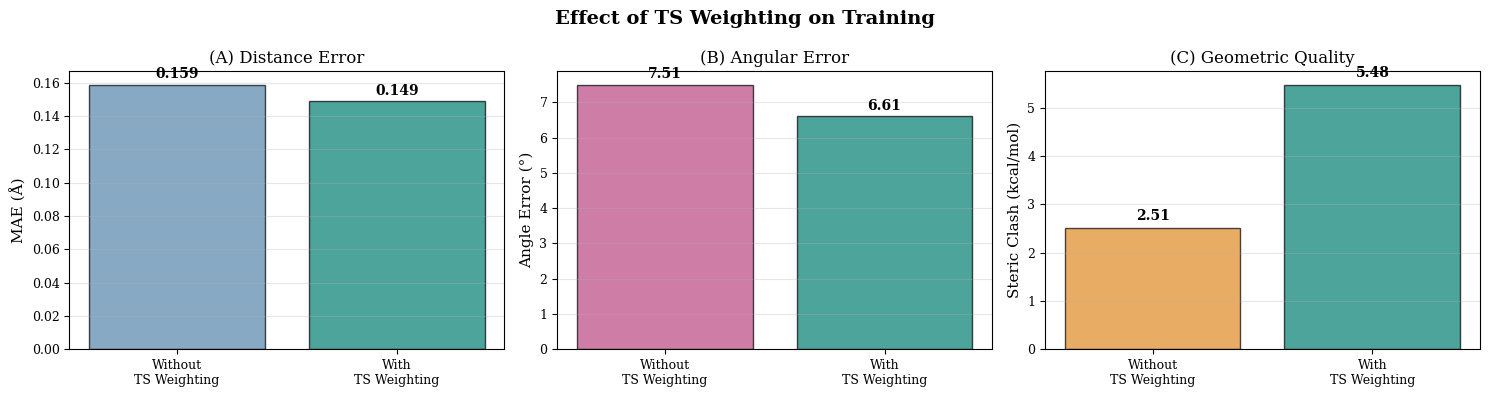


TS WEIGHTING IMPACT

Improvement with TS weighting:
  MAE: 6.3% reduction
  Angle Error: 12.0% reduction
  Steric Clash: -118.4% reduction


In [41]:
# ============================================================================
# FIGURE 5: TS Weighting Comparison
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Effect of TS Weighting on Training', fontweight='bold')

# Prepare data
configs = df_all_weights['config'].tolist()
labels = ['Without\nTS Weighting', 'With\nTS Weighting']

# Panel A: MAE Comparison
mae_values = df_all_weights['mae'].tolist()
axes[0].bar(labels, mae_values, color=[COLORS['mae'], COLORS['target']], 
            alpha=0.7, edgecolor='black')
axes[0].set_ylabel('MAE (Å)')
axes[0].set_title('(A) Distance Error')
axes[0].grid(True, alpha=0.3, axis='y')
# Add values on bars
for i, v in enumerate(mae_values):
    axes[0].text(i, v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

# Panel B: Angle Error Comparison
angle_values = df_all_weights['angle_error'].tolist()
axes[1].bar(labels, angle_values, color=[COLORS['angle'], COLORS['target']], 
            alpha=0.7, edgecolor='black')
axes[1].set_ylabel('Angle Error (°)')
axes[1].set_title('(B) Angular Error')
axes[1].grid(True, alpha=0.3, axis='y')
# Add values on bars
for i, v in enumerate(angle_values):
    axes[1].text(i, v + 0.1, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')

# Panel C: Steric Clash Comparison
clash_values = df_all_weights['steric_clash'].tolist()
axes[2].bar(labels, clash_values, color=[COLORS['clash'], COLORS['target']], 
            alpha=0.7, edgecolor='black')
axes[2].set_ylabel('Steric Clash (kcal/mol)')
axes[2].set_title('(C) Geometric Quality')
axes[2].grid(True, alpha=0.3, axis='y')
# Add values on bars
for i, v in enumerate(clash_values):
    axes[2].text(i, v + 0.1, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
# plt.savefig('fig5_ts_weighting.png', dpi=300, bbox_inches='tight')
plt.show()

# Print improvement statistics
print("\n" + "="*80)
print("TS WEIGHTING IMPACT")
print("="*80)
mae_improvement = (df_all_weights.iloc[0]['mae'] - df_all_weights.iloc[1]['mae']) / df_all_weights.iloc[0]['mae'] * 100
angle_improvement = (df_all_weights.iloc[0]['angle_error'] - df_all_weights.iloc[1]['angle_error']) / df_all_weights.iloc[0]['angle_error'] * 100
geometric_improvement = (df_all_weights.iloc[0]['steric_clash'] - df_all_weights.iloc[1]['steric_clash']) / df_all_weights.iloc[0]['steric_clash'] * 100
print(f"\nImprovement with TS weighting:")
print(f"  MAE: {mae_improvement:.1f}% reduction")
print(f"  Angle Error: {angle_improvement:.1f}% reduction")
print(f"  Steric Clash: {geometric_improvement:.1f}% reduction")
print("="*80)
